# This notebook demonstrates a series of experiments conducted with SPAg on the CASPER dataset

## Step 0. Setup the experiment

In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
import os
import pandas as pd
import numpy as np
from spag.evaluate import ForecastEstimator

In [11]:
input_data_dir = os.path.join('data', 'spag', 'input')
output_data_dir = os.path.join('data', 'spag', 'output')
model_directory = os.path.join('models', 'spag')

In [5]:
test = {}
valid = {}
models = {}

In [6]:
look_back_length = 60
horizon = 15

## Step 1. Load data

### Load test

In [20]:
for state in os.listdir(input_data_dir):
    test[state] = np.load(os.path.join(input_data_dir, state, 'test', 'targets.npy'))
    print(state, test[state].shape)

IMU_10Hz (700, 15, 9)
IMU_2Hz (700, 15, 9)
IMU_Acc_Gyro_20Hz (700, 15, 9)
IMU_earthquake (700, 15, 9)
IMU_hitting (700, 15, 9)
IMU_magnet (700, 15, 9)


### Load predictions

Here, we present an alternative approach to obtaining model results. Instead of directly executing pretrained models, as was done for the AI4I dataset, we utilize a prepared dataset for this purpose.

In [30]:
predictions = {}
for state in os.listdir(output_data_dir):
    predictions[state] = {}
    for model_name in os.listdir(os.path.join(output_data_dir, state)):
        predictions[state][model_name] = {}
        predictions[state][model_name]['targets'] = np.load(os.path.join(output_data_dir, state, model_name, 'targets.npy'))
        print(state, model_name, predictions[state][model_name]['targets'].shape)

IMU_10Hz gru_32_16_d005 (700, 15, 9)
IMU_10Hz gru_32_d005 (700, 15, 9)
IMU_10Hz lstm_32_16_d01 (700, 15, 9)
IMU_2Hz gru_32_16_d005 (700, 15, 9)
IMU_2Hz gru_32_d005 (700, 15, 9)
IMU_2Hz lstm_32_16_d01 (700, 15, 9)
IMU_Acc_Gyro_20Hz gru_32_16_d005 (700, 15, 9)
IMU_Acc_Gyro_20Hz gru_32_d005 (700, 15, 9)
IMU_Acc_Gyro_20Hz lstm_32_16_d01 (700, 15, 9)
IMU_earthquake gru_32_16_d005 (700, 15, 9)
IMU_earthquake gru_32_d005 (700, 15, 9)
IMU_earthquake lstm_32_16_d01 (700, 15, 9)
IMU_hitting gru_32_16_d005 (700, 15, 9)
IMU_hitting gru_32_d005 (700, 15, 9)
IMU_hitting lstm_32_16_d01 (700, 15, 9)
IMU_magnet gru_32_16_d005 (700, 15, 9)
IMU_magnet gru_32_d005 (700, 15, 9)
IMU_magnet lstm_32_16_d01 (700, 15, 9)


## Step 2. Evaluation

Connected with Table 7, regression models GRU-1, GRU-3, LSTM-1 as well as Naive and Mean approaches

In [31]:
estimators = {}
for state, data in test.items():
    print(state)
    estimator = ForecastEstimator()
    estimator.set_true_values(data)
    for model_name, preds in predictions[state].items():
        estimator.set_pred_values(preds['targets'], model_name=model_name)
    estimator.estimate()
    estimators[state] = estimator

IMU_10Hz
IMU_2Hz
IMU_Acc_Gyro_20Hz
IMU_earthquake
IMU_hitting
IMU_magnet


In [32]:
result = pd.DataFrame(columns=['state', 'model_name', 'MSE', 'MAE'])
i = 0
for state, estimator in estimators.items():
    model_names = list(estimator.pred.keys())
    for model_name in model_names:
        result.loc[i, 'state'] = state
        result.loc[i, 'model_name'] = model_name
        result.loc[i, 'MSE'] = estimator.quality.loc['ALL_FEATURES', f'{model_name}_MSE']
        result.loc[i, 'MAE'] = estimator.quality.loc['ALL_FEATURES', f'{model_name}_MAE']
        i = i + 1
result

,state,model_name,MSE,MAE
0,IMU_10Hz,gru_32_16_d005,0.00053,0.01286
1,IMU_10Hz,gru_32_d005,0.00054,0.01274
2,IMU_10Hz,lstm_32_16_d01,0.000632,0.01391
3,IMU_2Hz,gru_32_16_d005,0.003175,0.03095
4,IMU_2Hz,gru_32_d005,0.001677,0.0224
5,IMU_2Hz,lstm_32_16_d01,0.003404,0.03119
6,IMU_Acc_Gyro_20Hz,gru_32_16_d005,0.00073,0.01117
7,IMU_Acc_Gyro_20Hz,gru_32_d005,0.000764,0.01137
8,IMU_Acc_Gyro_20Hz,lstm_32_16_d01,0.000775,0.0112
9,IMU_earthquake,gru_32_16_d005,0.003865,0.03523


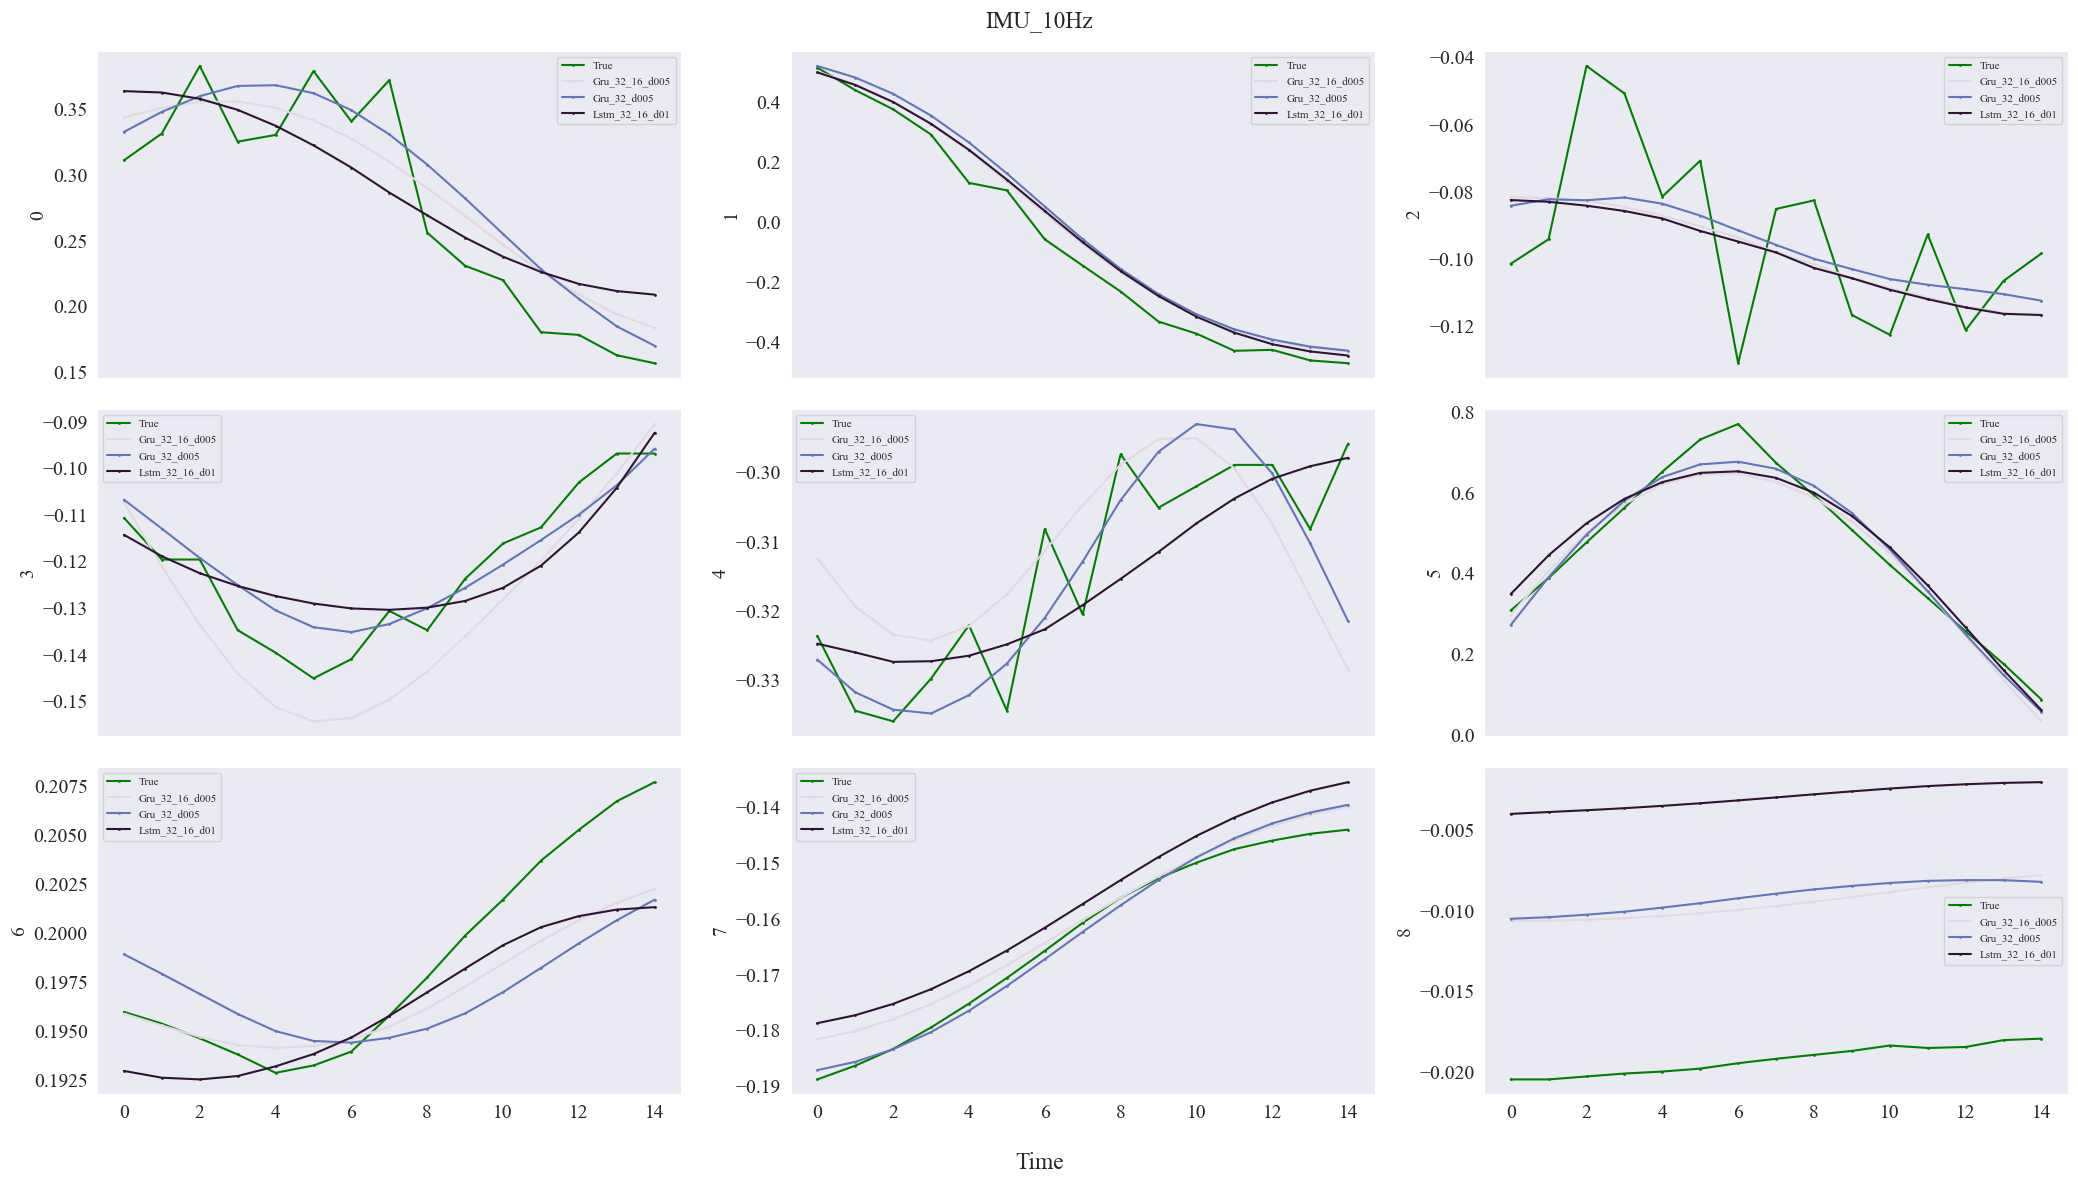

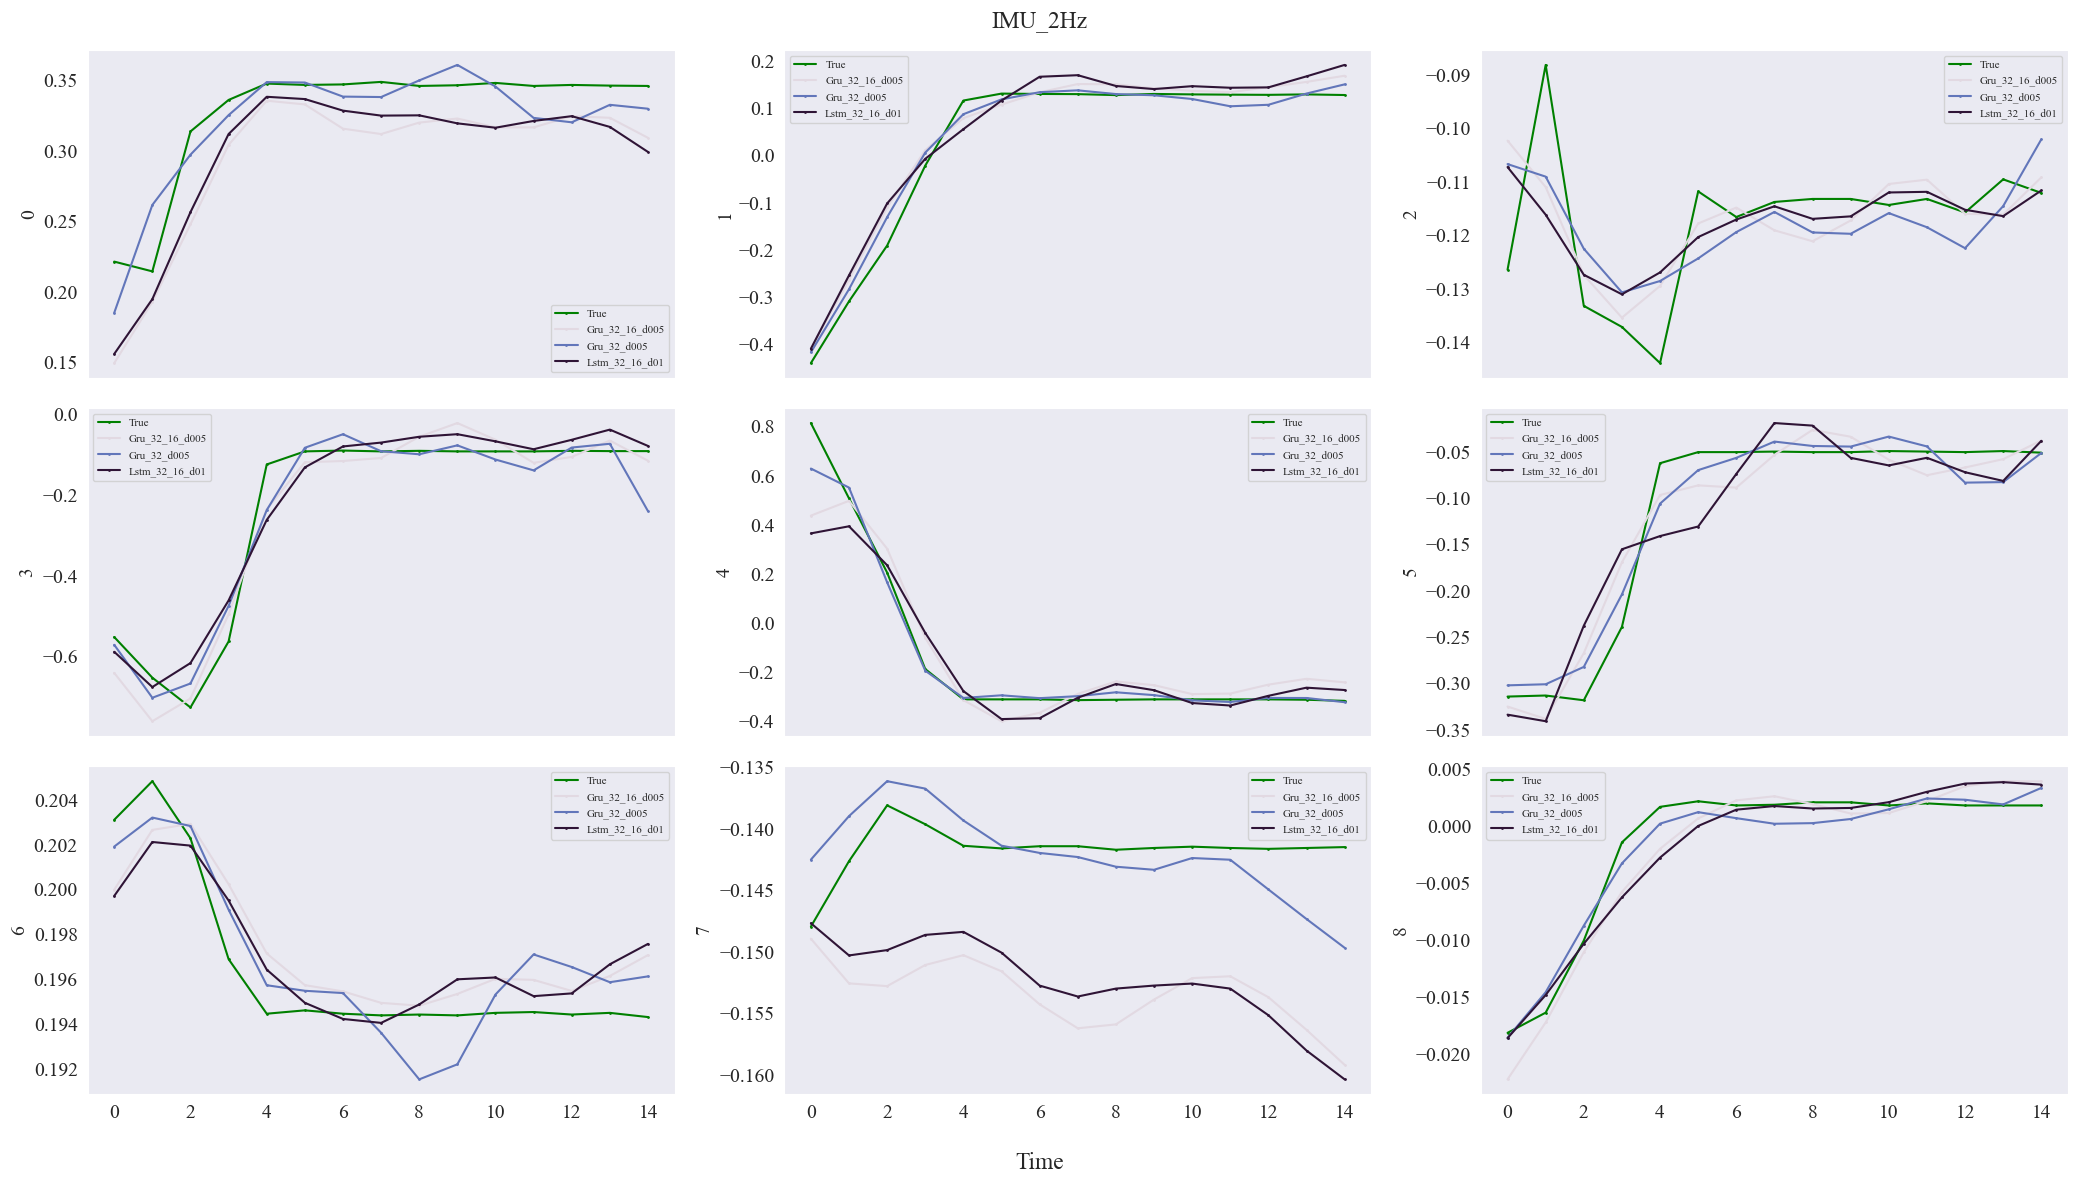

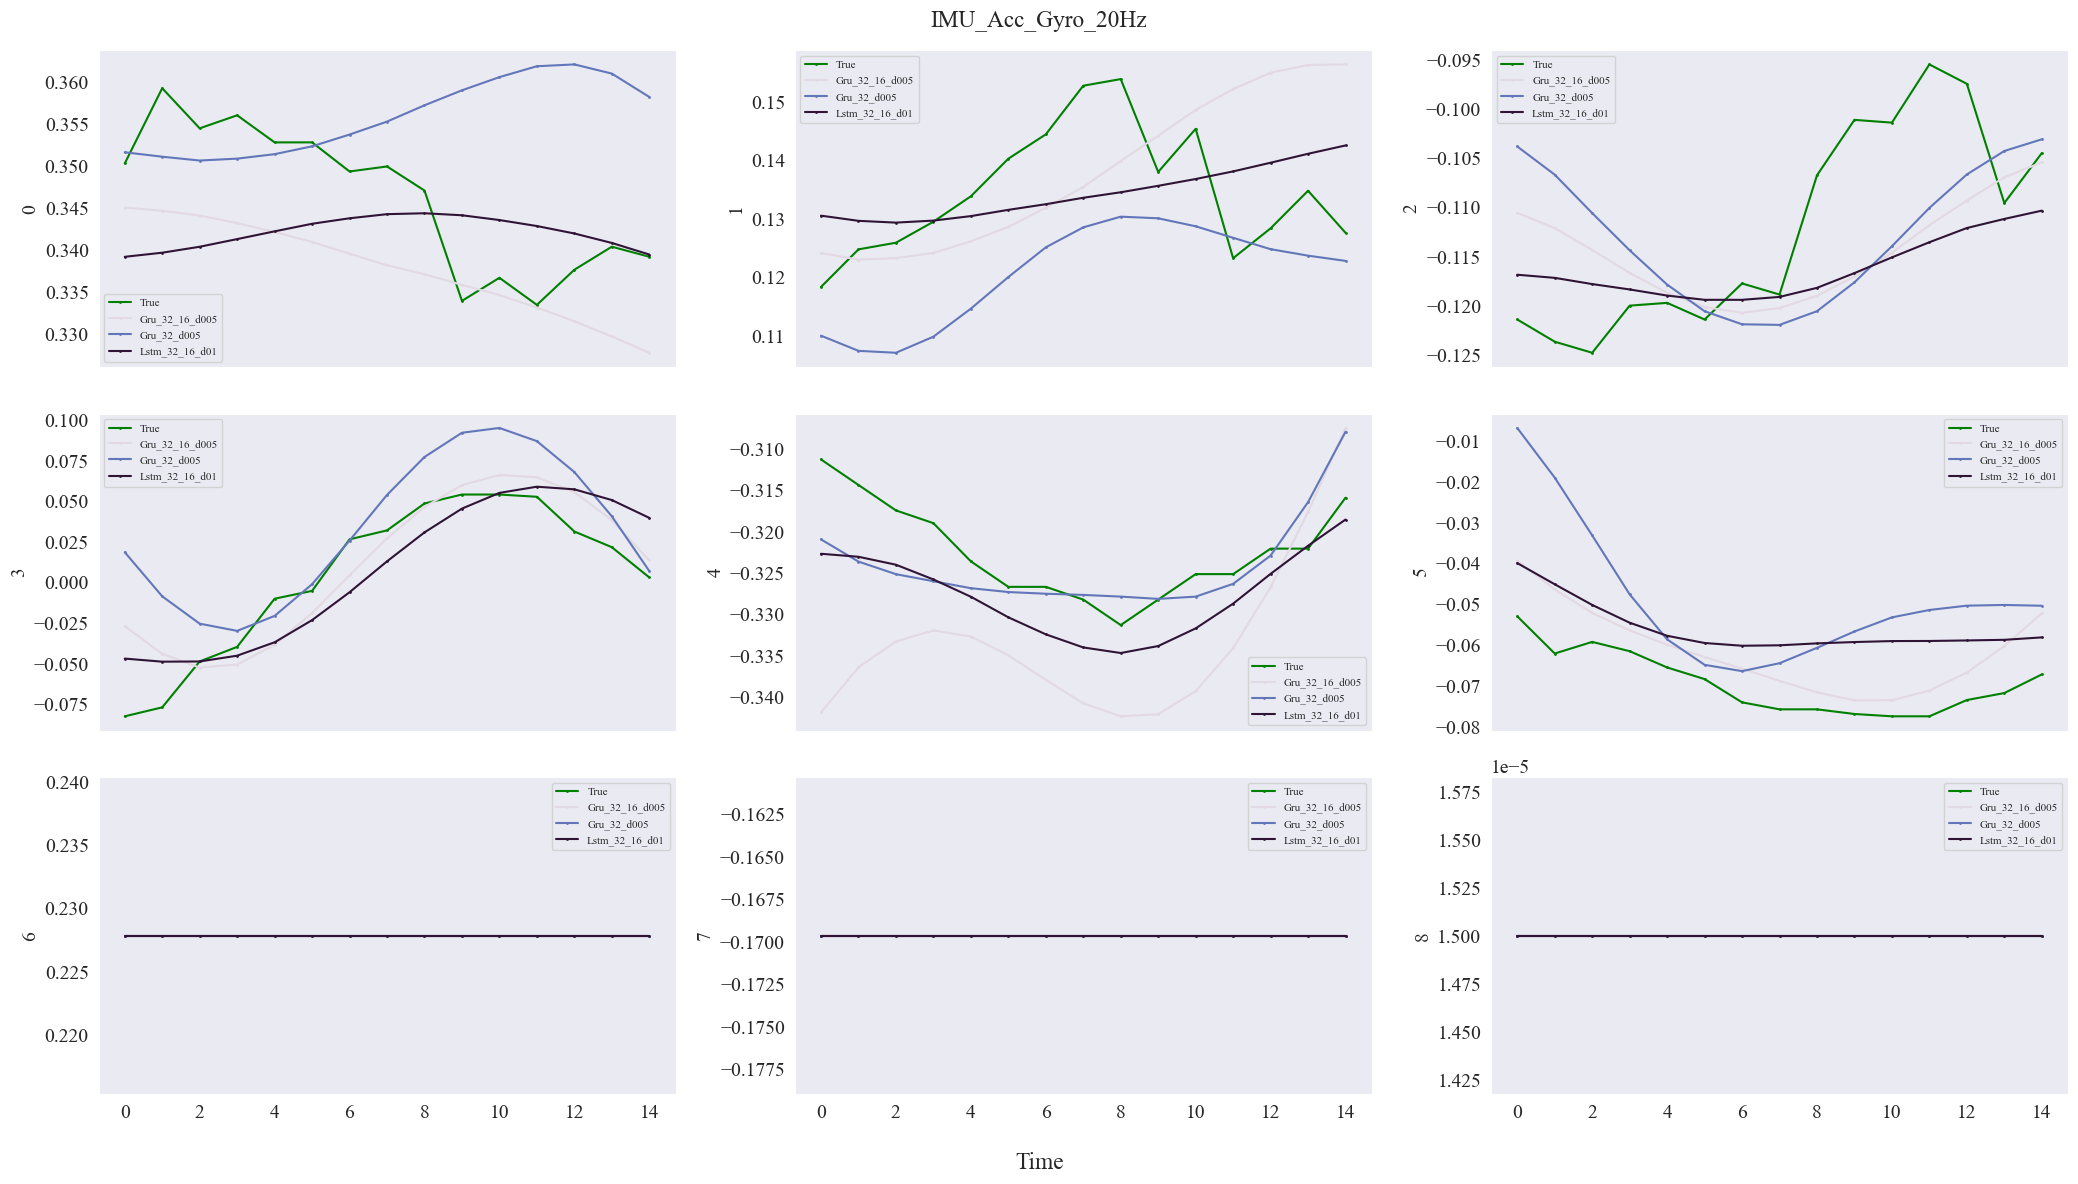

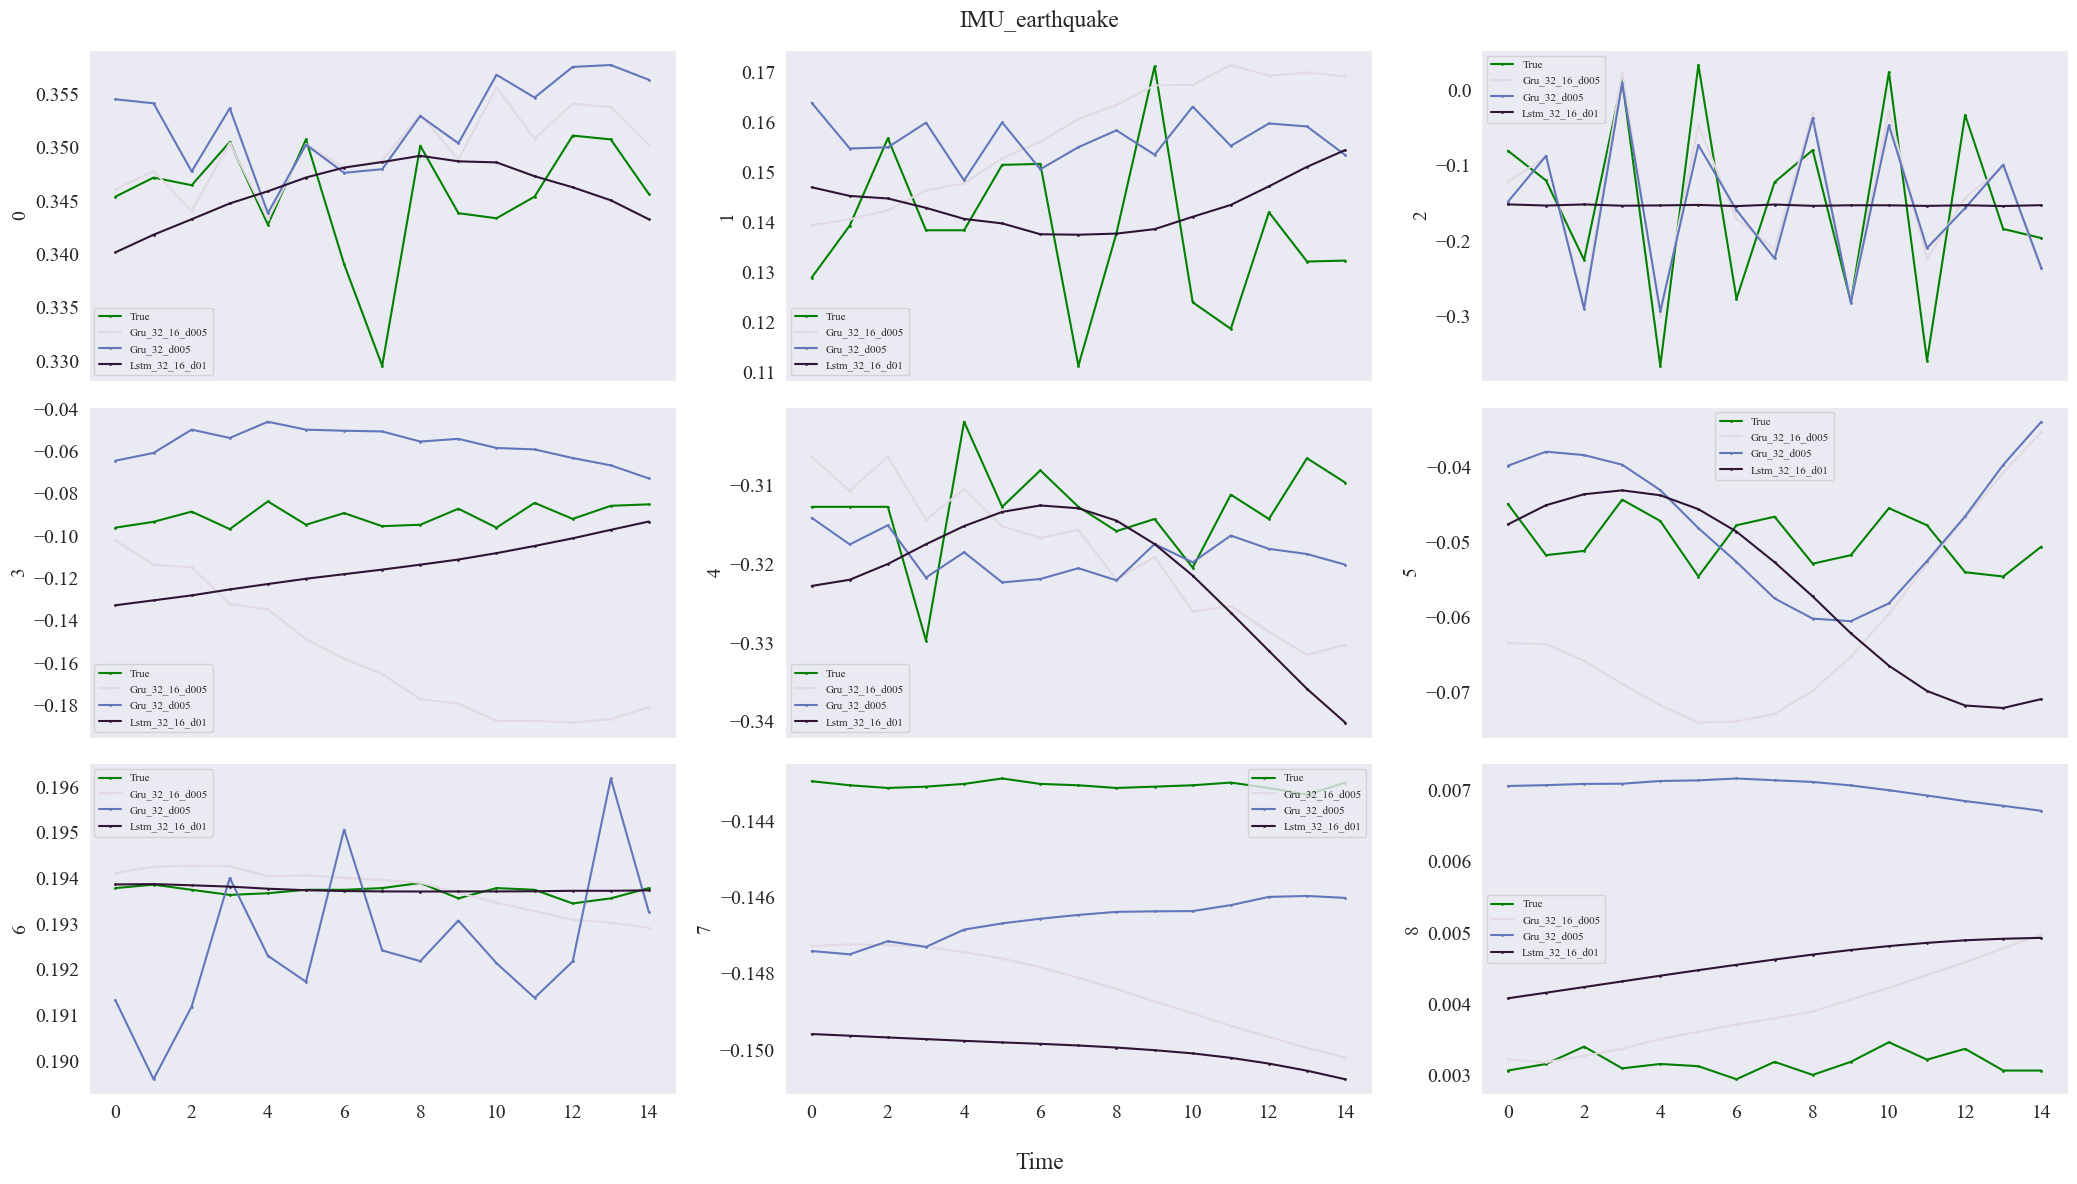

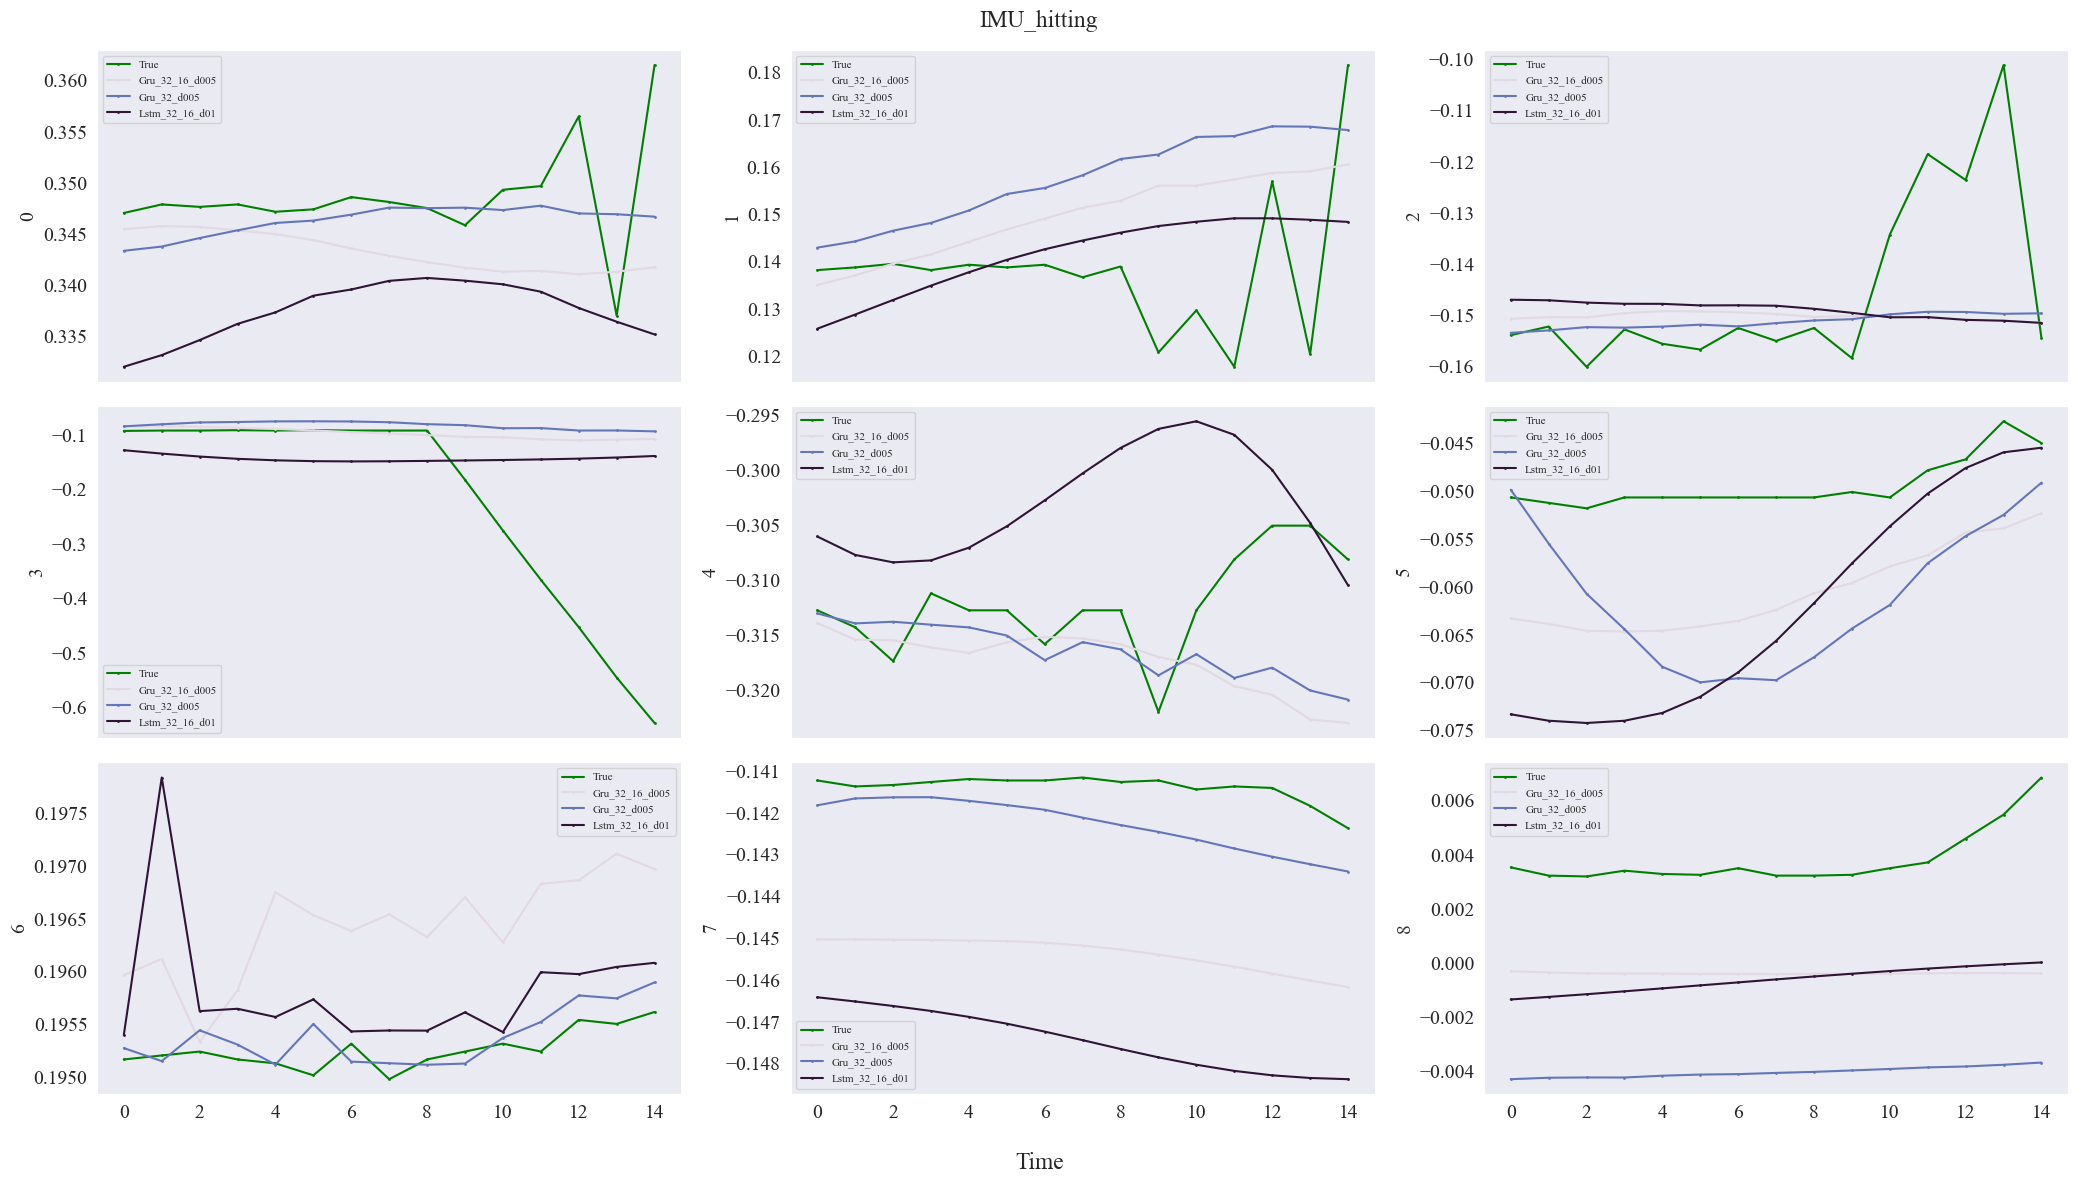

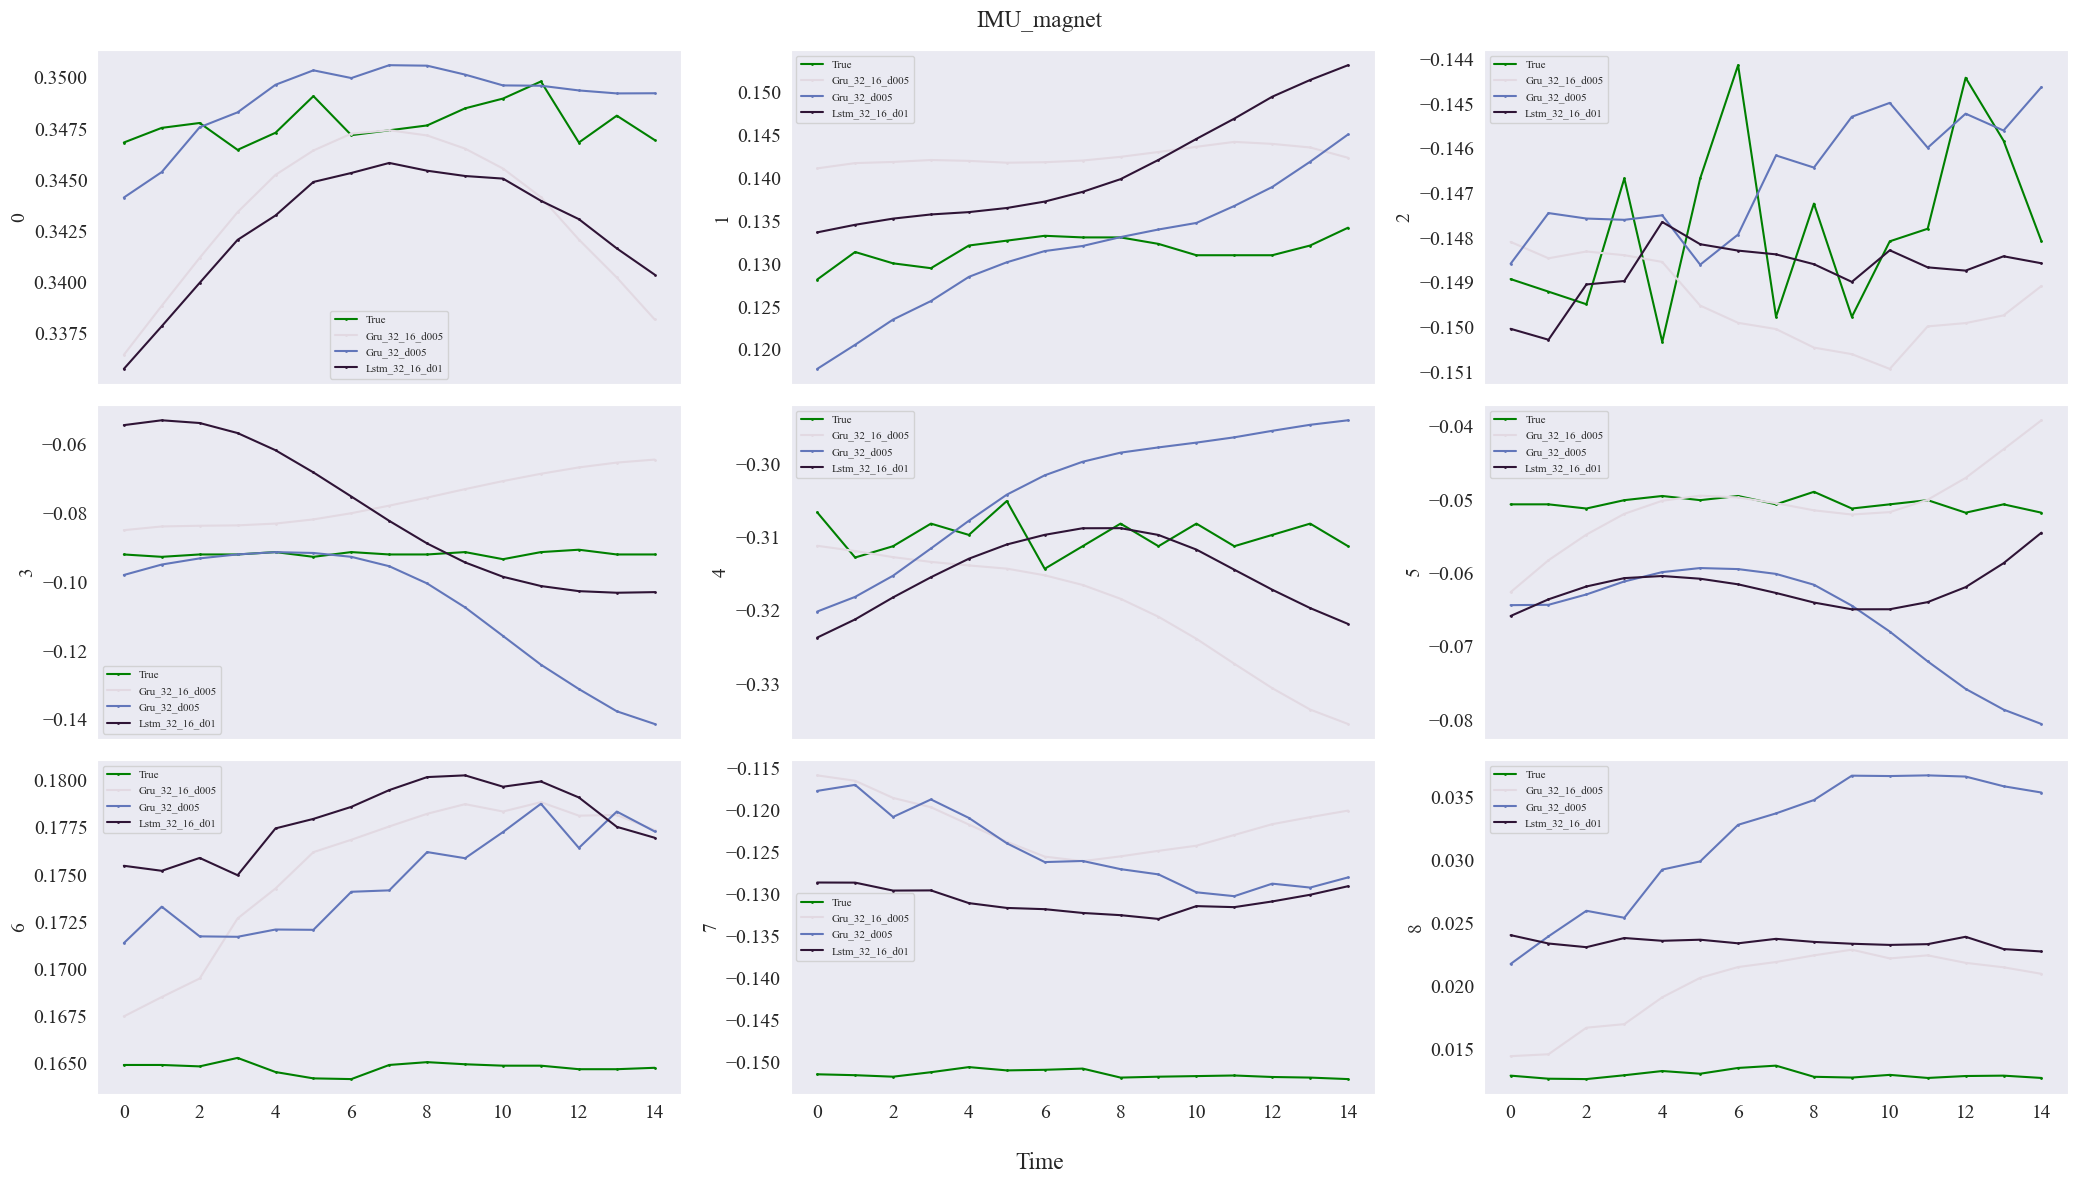

In [33]:
for state, estimator in estimators.items():
    estimator.draw(size=1, draw_horizon=None, title=state)

This concludes the demonstration for the CASPER dataset.